# Variational Autoencoder - on the MNIST dataset:

The following is an illustration/exercise in using a **Variational** Auto-Encoder on the MNIST image data.

The variational AE is very similar to a "normal" AE, but requires the latent space to be Gaussianly distributed (of course in multiple dimensions). This makes it possible to **generate** new instances by selecting a random number in this latent space, and then applying the decoder. This is not possible for a "normal" AE, where the latent space has more fractal distributions from which one can not choose a random number and expect to get something similar.

The code is adapted from this [post](https://medium.com/@rekalantar/variational-auto-encoder-vae-pytorch-tutorial-dce2d2fe0f5f).

***

Last Update: 2026-10-28

In [1]:
import torch
import numpy as np
import torch.nn as nn
from torch.optim import Adam
import matplotlib.pyplot as plt
import matplotlib
#matplotlib.use('Agg') 
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from mpl_toolkits.axes_grid1 import ImageGrid
from torchvision.utils import save_image, make_grid
from PIL import Image

In [2]:
# create a transform to apply to each datapoint
transform = transforms.Compose([transforms.ToTensor()])

# download the MNIST datasets
path = '~/datasets'
train_dataset = MNIST(path, transform=transform, download=True)
test_dataset  = MNIST(path, transform=transform, download=True)

# create train and test dataloaders
batch_size = 100
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

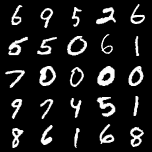

In [3]:
# Get one batch
images, _ = next(iter(train_loader))

# Move to CPU and detach
images = images.cpu().detach()

# Make a 5x5 grid
grid_img = make_grid(images[:25], nrow=5, padding=2)

# Convert CHW -> HWC and scale to [0,255]
grid_np = (grid_img.permute(1,2,0).numpy() * 255).astype('uint8')

# Convert to PIL image and display inline
pil_img = Image.fromarray(grid_np)
display(pil_img)


In [4]:
class Encoder(nn.Module):

    def __init__(self, input_dim=784, hidden_dim=512, latent_dim=256):
        super(Encoder, self).__init__()

        self.linear1 = nn.Linear(input_dim, hidden_dim)
        self.linear2 = nn.Linear(hidden_dim, hidden_dim)
        self.mean = nn.Linear(hidden_dim, latent_dim)
        self.var = nn.Linear (hidden_dim, latent_dim)
        self.LeakyReLU = nn.LeakyReLU(0.2)
        self.training = True

    def forward(self, x):
        x = self.LeakyReLU(self.linear1(x))
        x = self.LeakyReLU(self.linear2(x))

        mean = self.mean(x)
        log_var = self.var(x)
        return mean, log_var

In [5]:
class Decoder(nn.Module):

    def __init__(self, output_dim=784, hidden_dim=512, latent_dim=256):
        super(Decoder, self).__init__()

        self.linear2 = nn.Linear(latent_dim, hidden_dim)
        self.linear1 = nn.Linear(hidden_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim, output_dim)
        self.LeakyReLU = nn.LeakyReLU(0.2)

    def forward(self, x):
        x = self.LeakyReLU(self.linear2(x))
        x = self.LeakyReLU(self.linear1(x))

        x_hat = torch.sigmoid(self.output(x))
        return x_hat

In [6]:
class VAE(nn.Module):

    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=200, device=device):
        super(VAE, self).__init__()

        # encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, latent_dim),
            nn.LeakyReLU(0.2)
            )

        # latent mean and variance
        self.mean_layer = nn.Linear(latent_dim, 2)
        self.logvar_layer = nn.Linear(latent_dim, 2)

        # decoder
        self.decoder = nn.Sequential(
            nn.Linear(2, latent_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(latent_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
            )

    def encode(self, x):
        x = self.encoder(x)
        mean, logvar = self.mean_layer(x), self.logvar_layer(x)
        return mean, logvar

    def reparameterization(self, mean, var):
        epsilon = torch.randn_like(var).to(device)
        z = mean + var*epsilon
        return z

    def decode(self, x):
        return self.decoder(x)

    def forward(self, x):
        mean, logvar = self.encode(x)
        z = self.reparameterization(mean, logvar)
        x_hat = self.decode(z)
        return x_hat, mean, log_var

    def forward(self, x):
        mean, log_var = self.encode(x)
        z = self.reparameterization(mean, torch.exp(0.5 * log_var))
        x_hat = self.decode(z)
        return x_hat, mean, log_var

In [7]:
model = VAE().to(device)
optimizer = Adam(model.parameters(), lr=1e-3)

In [8]:
def loss_function(x, x_hat, mean, log_var):
    reproduction_loss = nn.functional.binary_cross_entropy(x_hat, x, reduction='sum')
    KLD = - 0.5 * torch.sum(1+ log_var - mean.pow(2) - log_var.exp())

    return reproduction_loss + KLD

In [9]:
def train(model, optimizer, epochs, device, x_dim=784):
    model.train()
    for epoch in range(epochs):
        overall_loss = 0
        for batch_idx, (x, _) in enumerate(train_loader):
            x = x.view(batch_size, x_dim).to(device)

            optimizer.zero_grad()

            x_hat, mean, log_var = model(x)
            loss = loss_function(x, x_hat, mean, log_var)

            overall_loss += loss.item()

            loss.backward()
            optimizer.step()

        print("\tEpoch", epoch + 1, "\tAverage Loss: ", overall_loss/(batch_idx*batch_size))
    return overall_loss

In [10]:
train(model, optimizer, epochs=50, device=device)

	Epoch 1 	Average Loss:  179.28718562513043
	Epoch 2 	Average Loss:  161.74721056904738
	Epoch 3 	Average Loss:  157.5970132838585
	Epoch 4 	Average Loss:  155.1111018690004
	Epoch 5 	Average Loss:  153.45510737296536
	Epoch 6 	Average Loss:  152.16029166449292
	Epoch 7 	Average Loss:  150.93789494535162
	Epoch 8 	Average Loss:  149.94424380803943
	Epoch 9 	Average Loss:  149.2674016101054
	Epoch 10 	Average Loss:  148.33063921640235
	Epoch 11 	Average Loss:  147.76171995643782
	Epoch 12 	Average Loss:  147.2138842243583
	Epoch 13 	Average Loss:  146.67535730123123
	Epoch 14 	Average Loss:  146.29145012194803
	Epoch 15 	Average Loss:  145.82844111931345
	Epoch 16 	Average Loss:  145.53810507747286
	Epoch 17 	Average Loss:  145.1527850942978
	Epoch 18 	Average Loss:  144.8662215345889
	Epoch 19 	Average Loss:  144.64845711276607
	Epoch 20 	Average Loss:  144.40572557452526
	Epoch 21 	Average Loss:  144.08230651345994
	Epoch 22 	Average Loss:  143.7793181833003
	Epoch 23 	Average Loss:  

8393102.579101562

In [11]:
from IPython.display import display
from PIL import Image
import numpy as np

def generate_digit(mean, var):
    z_sample = torch.tensor([[mean, var]], dtype=torch.float).to(device)
    x_decoded = model.decode(z_sample)
    digit = x_decoded.detach().cpu().numpy().reshape(28, 28)

    # Convert to [0,255] grayscale image
    digit_img = (digit * 255).clip(0,255).astype(np.uint8)
    pil_img = Image.fromarray(digit_img, mode='L')

    print(f"Decoded digit for latent vector [{mean}, {var}]")
    display(pil_img)


In [12]:
#img1: mean0, var1 / img2: mean1, var0
generate_digit(0.0, 1.0), generate_digit(1.0, 0.0)

Decoded digit for latent vector [0.0, 1.0]


Decoded digit for latent vector [1.0, 0.0]


(None, None)

In [13]:
import numpy as np
import torch
from PIL import Image
from IPython.display import display

def plot_latent_space(model, scale=5.0, n=25, digit_size=28):
    figure = np.zeros((digit_size * n, digit_size * n), dtype=np.float32)
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    model_device = next(model.parameters()).device  # Get model device

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = torch.tensor([[xi, yi]], dtype=torch.float, device=model_device)
            with torch.no_grad():
                x_decoded = model.decode(z_sample)
            digit = x_decoded[0].detach().cpu().numpy().reshape(digit_size, digit_size)
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size
            ] = digit

    # Convert to PIL and display inline
    figure_img = (figure * 255).clip(0, 255).astype(np.uint8)
    pil_img = Image.fromarray(figure_img, mode='L')
    display(pil_img)



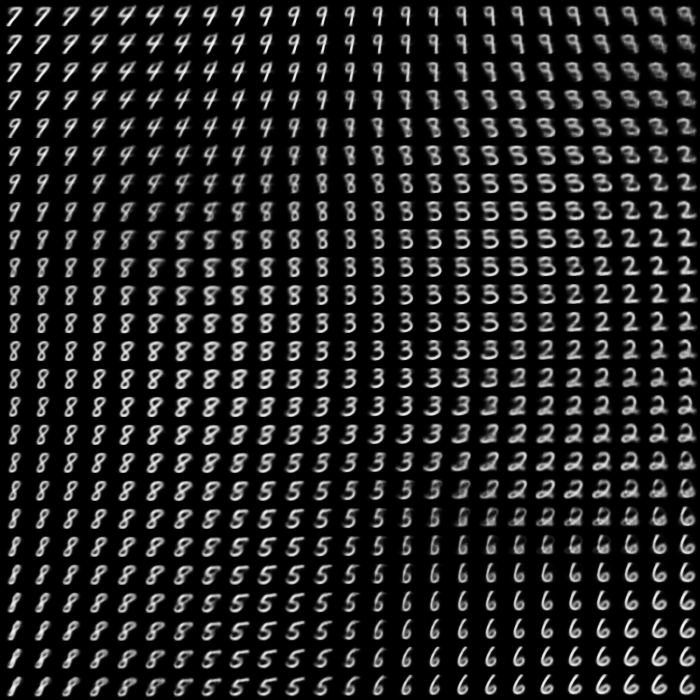

In [14]:
plot_latent_space(model, scale=1.0)

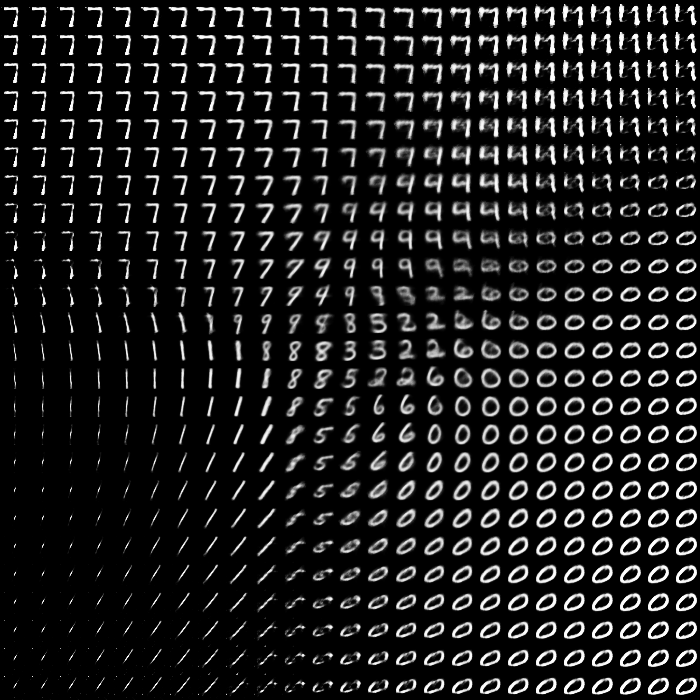

In [15]:
plot_latent_space(model, scale=5.0)